## Data Preparation

## Set up dataloaders

In [1]:
import os
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset
import torchvision.transforms as transforms
import itertools


class BlindSpotDataset(Dataset):

    def __init__(self,
                 root_dir,
                 split='train',
                 pre_seq_length=30,
                 aft_seq_length=5,
                 suffix='.mp4',
                 frame_size=256,
                 get_merged = 0,
                 get_differenced = 0,
                 alternate_merge_diff = 0,
                 get_raw = 30,
                 get_added = False,
                 step = 2
                ):
        
        self.pre_seq_length = pre_seq_length
        self.aft_seq_length = aft_seq_length
        self.total_frames = pre_seq_length + aft_seq_length
        self.frame_size = frame_size
        self.get_merged = get_merged
        self.get_differenced = get_differenced
        self.alternate_merge_diff = alternate_merge_diff
        self.offset = 30-pre_seq_length
        self.get_raw = get_raw
        self.get_added = get_added
        self.step = step

        self.mean = None
        self.std = None
        self.data_name = "blind_spot"
        
        self.folder = os.path.join(root_dir, split)
        self.video_paths = [
            os.path.join(self.folder, f)
            for f in os.listdir(self.folder)
            if f.endswith(suffix)
        ]

    def __len__(self):
        return len(self.video_paths)

    def _sample_frames(self, video_path):
        video = cv2.VideoCapture(video_path)
        total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

        frame_idxs = np.linspace(
            0, total_frames - 1,
            self.total_frames+self.offset,
            dtype=int
        )

        frames = []

        for idx in frame_idxs:
            video.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = video.read()
            if not ret:
                continue

            # Convert to grayscale
            # frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            frame = cv2.resize(frame, (self.frame_size, self.frame_size))

            frames.append(frame)

        video.release()

        frames = np.stack(frames)#.transpose(0, 3, 1, 2) # (T, H, W, C) to (T, C, H, W)
        
        frames = frames[self.offset:]
        return frames


    def mask_ego_vehicle_soft(self, img, mask_radius=5, feather=2):
        h, w = img.shape[:2]
        cx, cy = w // 2, h // 2
    
        y, x = np.ogrid[:h, :w]
        dist = np.sqrt((x - cx)**2 + (y - cy)**2)
    
        mask = np.ones((h, w), dtype=np.float32)
    
        inner = dist <= mask_radius
        outer = (dist > mask_radius) & (dist < mask_radius + feather)
    
        mask[inner] = 0.0
        mask[outer] = (dist[outer] - mask_radius) / feather
    
        masked = img.astype(np.float32) * mask[:, :, None]
    
        return masked
    
    
    def gradient_magnitude(self, img):
        img = img.astype(np.float32)
    
        gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    
        mag = np.sqrt(gx**2 + gy**2)
        mag = np.sum(mag, axis=2)
    
        return mag
    
    
    def compute_sequential_translations(self, images):
   
        h, w = images[0].shape[:2]
        window = cv2.createHanningWindow((w, h), cv2.CV_32F)
    
        global_translations = [(0.0, 0.0)]
        cumulative_dx = 0.0
        cumulative_dy = 0.0
    
        prev_img = images[0]
    
        prev_proc = self.gradient_magnitude(
            self.mask_ego_vehicle_soft(prev_img)
        ) * window
    
        for i in range(1, len(images)):
    
            curr_img = images[i]
    
            curr_proc = self.gradient_magnitude(
                self.mask_ego_vehicle_soft(curr_img)
            ) * window
    
            shift, response = cv2.phaseCorrelate(prev_proc, curr_proc)
    
            dx, dy = shift
            dx = -dx
            dy = -dy
    
            # accumulate global position
            cumulative_dx += dx
            cumulative_dy += dy
    
            global_translations.append((cumulative_dx, cumulative_dy))
    
            prev_proc = curr_proc
    
        return np.array(global_translations)
    
    
    def crop_to_second_frame(self, merged, dx, dy, offset_x, offset_y, img2_shape):
    
        h2, w2 = img2_shape[:2]
    
        x_start = int(round(dx + offset_x))
        y_start = int(round(dy + offset_y))
    
        x_end = x_start + w2
        y_end = y_start + h2
    
        cropped = merged[y_start:y_end, x_start:x_end]
    
        return cropped
    
    
    def shift_and_merge_images(self, images):
        # Estimate Translations
        translations = self.compute_sequential_translations(images)
        translations = np.array(translations)
    
        # compute global canvas bounds
        # determine all image corners in global frame
        corners = []
    
        for (dx, dy), img in zip(translations, images):
            h, w = img.shape[:2]
            corners.append([
                dx, dy,
                dx + w, dy,
                dx + w, dy + h,
                dx, dy + h
            ])
    
        corners = np.array(corners).reshape(-1, 2)
    
        xmin, ymin = np.floor(corners.min(axis=0)).astype(int)
        xmax, ymax = np.ceil(corners.max(axis=0)).astype(int)
    
        canvas_width = xmax - xmin
        canvas_height = ymax - ymin
    
        # offset so everything is positive
        offset_x = -xmin
        offset_y = -ymin
    
        # warp images into canvas
        stack = []
    
        for (dx, dy), img in zip(translations, images):
    
            M = np.array([
                [1, 0, dx + offset_x],
                [0, 1, dy + offset_y]
            ], dtype=np.float32)
    
            warped = cv2.warpAffine(
                img,
                M,
                (canvas_width, canvas_height),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_CONSTANT,
                borderValue=(0, 0, 0)
            )
    
            stack.append(warped.astype(np.float32))
    
        stack = np.stack(stack, axis=0)
    

        # Masked Median Blending
        # Mask is True where pixel is NOT black
        valid_mask = np.any(stack > 40, axis=-1)
    
        merged = np.zeros_like(stack[0])
        differenced = np.zeros_like(stack[0])
    
        for c in range(3):
            channel = stack[:, :, :, c]
    
            # Replace invalid pixels with NaN
            channel_masked = np.where(valid_mask, channel, np.nan)
    
            # Median ignoring NaNs
            merged[:, :, c] = np.nanmedian(channel_masked, axis=0)

            # subtract image from merged map to get difference frame
            differenced[:, :, c] = merged[:, :, c] - channel_masked[1]
    
        # Replace remaining NaNs (areas never seen) with black
        merged = np.nan_to_num(merged, nan=0.0)
        differenced = np.nan_to_num(differenced, nan=0.0)
    
        merged = np.clip(merged, 0, 255).astype(np.uint8)
        differenced = np.clip(differenced, 0, 255).astype(np.uint8)
    
        dx = translations[1][0]
        dy = translations[1][1]
    
        merged = self.crop_to_second_frame(
            merged,
            dx,
            dy,
            offset_x,
            offset_y,
            images[1].shape
        )

        differenced = self.crop_to_second_frame(
            differenced,
            dx,
            dy,
            offset_x,
            offset_y,
            images[1].shape
        )
    
        return merged, differenced


    def __getitem__(self, idx):

        video_path = self.video_paths[idx]

        frames = self._sample_frames(video_path)

        x = frames[:self.pre_seq_length]
        y = frames[self.pre_seq_length:]

        if self.get_merged > 0 or self.get_differenced > 0:
            merged_frames = []
            differenced_frames = []
            
            step = self.step
            for i in range(0, self.pre_seq_length-1, step):
                if (i+step-1) > self.pre_seq_length-1:
                    continue
                merged, differenced = self.shift_and_merge_images([x[i], x[i+step-1]])
                merged_frames.append(merged)
                differenced_frames.append(differenced)

            input_frames = []
            if self.get_added:
                    added = np.clip(np.array(merged_frames)+np.array(differenced_frames), 0, 255).astype(np.uint8)
                    for i in range(0, len(added)):
                        input_frames.append(added[i].astype(np.float32) / 255.0)
                    if self.get_raw > 0:
                        for i in range(0, self.get_raw):
                                input_frames.append(x[len(x)-self.get_raw+i].astype(np.float32) / 255.0)
            elif self.get_merged > 0 and self.get_differenced == 0:
                if self.alternate_merge_diff == 0:
                    for i in range(0, self.get_merged):
                        input_frames.append(merged_frames[len(merged_frames)-self.get_merged+i].astype(np.float32) / 255.0)
                    if self.get_raw > 0:
                        for i in range(0, self.get_raw):
                                input_frames.append(x[len(x)-self.get_raw+i].astype(np.float32) / 255.0)
                elif self.alternate_merge_diff == 3:
                    for i in range(0, len(merged_frames), 3):
                        input_frames.append(merged_frames[i].astype(np.float32) / 255.0)
                        input_frames.append(merged_frames[i+1].astype(np.float32) / 255.0)
                        input_frames.append(merged_frames[i+2].astype(np.float32) / 255.0)
                        if self.get_raw > 0:
                            input_frames.append(x[i+2].astype(np.float32) / 255.0)
            elif self.get_differenced > 0 and self.get_merged == 0:
                if self.alternate_merge_diff == 0:
                    for i in range(0, self.get_differenced):
                        input_frames.append(differenced_frames[len(differenced_frames)-self.get_differenced+i].astype(np.float32) / 255.0)
                    if self.get_raw > 0:
                        for i in range(0, self.get_raw):
                                input_frames.append(x[len(x)-self.get_raw+i].astype(np.float32) / 255.0)
                # elif self.alternate_merge_diff == 3:
                #     for i in range(0, len(merged_frames), 3):
                #         input_frames.append(merged_frames[i].astype(np.float32) / 255.0)
                #         input_frames.append(merged_frames[i+1].astype(np.float32) / 255.0)
                #         input_frames.append(merged_frames[i+2].astype(np.float32) / 255.0)
                #         input_frames.append(differenced_frames[i+2].astype(np.float32) / 255.0)
                #         if self.get_raw > 0:
                #             input_frames.append(x[i+2].astype(np.float32) / 255.0)
            elif self.get_differenced > 0 and self.get_merged > 0:
                if self.alternate_merge_diff == 0:
                    for i in range(0, self.get_merged):
                        input_frames.append(merged_frames[len(merged_frames)-self.get_merged+i].astype(np.float32) / 255.0)
                    for i in range(0, self.get_differenced):
                        input_frames.append(differenced_frames[len(differenced_frames)-self.get_differenced+i].astype(np.float32) / 255.0)
                    if self.get_raw > 0:
                        for i in range(0, self.get_raw):
                                input_frames.append(x[len(x)-self.get_raw+i].astype(np.float32) / 255.0)
                elif self.alternate_merge_diff == 1:
                    for i in range(0, len(merged_frames)):
                        input_frames.append(merged_frames[i].astype(np.float32) / 255.0)
                        input_frames.append(differenced_frames[i].astype(np.float32) / 255.0)
                    if self.get_raw > 0:
                        for i in range(0, self.get_raw):
                                input_frames.append(x[len(x)-self.get_raw+i].astype(np.float32) / 255.0)
                elif self.alternate_merge_diff == 3:
                    for i in range(0, len(merged_frames), 3):
                        input_frames.append(merged_frames[i].astype(np.float32) / 255.0)
                        input_frames.append(merged_frames[i+1].astype(np.float32) / 255.0)
                        input_frames.append(merged_frames[i+2].astype(np.float32) / 255.0)
                        if self.get_raw > 0:
                            input_frames.append(x[i+2].astype(np.float32) / 255.0)
                        input_frames.append(differenced_frames[i+2].astype(np.float32) / 255.0)
            # keep this or no?
            x = x.astype(np.float32) / 255.0
            x = np.stack(input_frames).transpose(0, 3, 1, 2) # (T, H, W, C) to (T, C, H, W)
            
        else:
            input_frames = []
            for i in range(0, self.get_raw):
                input_frames.append(x[self.offset+i].astype(np.float32) / 255.0)
            # x = x.astype(np.float32) / 255.0
            # x = np.stack(x).transpose(0, 3, 1, 2) # (T, H, W, C) to (T, C, H, W)
            # x = x.astype(np.float32) / 255.0
            x = np.stack(input_frames).transpose(0, 3, 1, 2) # (T, H, W, C) to (T, C, H, W)
        
        # Convert to tensor
        x = torch.from_numpy(x)

        y = y.astype(np.float32) / 255.0
        y = np.stack(y).transpose(0, 3, 1, 2) # (T, H, W, C) to (T, C, H, W)
        y = torch.from_numpy(y)

        return x, y

In [2]:
from torch.utils.data import DataLoader

batch_size = 1
num_workers = 8

root_dir = '/mnt/active_storage/Knut/LimitedFOVData/final_data_color/'

pre_seq_length = 30
aft_seq_length = 5
frame_size = 256
get_merged = 0
get_differenced = 0
alternate_merge_diff = 0
get_raw = 30
get_added = False
step = 3

train_dataset = BlindSpotDataset(
    root_dir=root_dir,
    split='train',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size,
    get_merged = get_merged,
    get_differenced = get_differenced,
    alternate_merge_diff = alternate_merge_diff,
    get_raw = get_raw,
    get_added = get_added,
    step = step
)

val_dataset = BlindSpotDataset(
    root_dir=root_dir,
    split='val',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size,
    get_merged = get_merged,
    get_differenced = get_differenced,
    alternate_merge_diff = alternate_merge_diff,
    get_raw = get_raw,
    get_added = get_added,
    step = step
)

test_dataset = BlindSpotDataset(
    root_dir=root_dir,
    split='test',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size,
    get_merged = get_merged,
    get_differenced = get_differenced,
    alternate_merge_diff = alternate_merge_diff,
    get_raw = get_raw,
    get_added = get_added,
    step = step
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)



(30, 3, 256, 256)


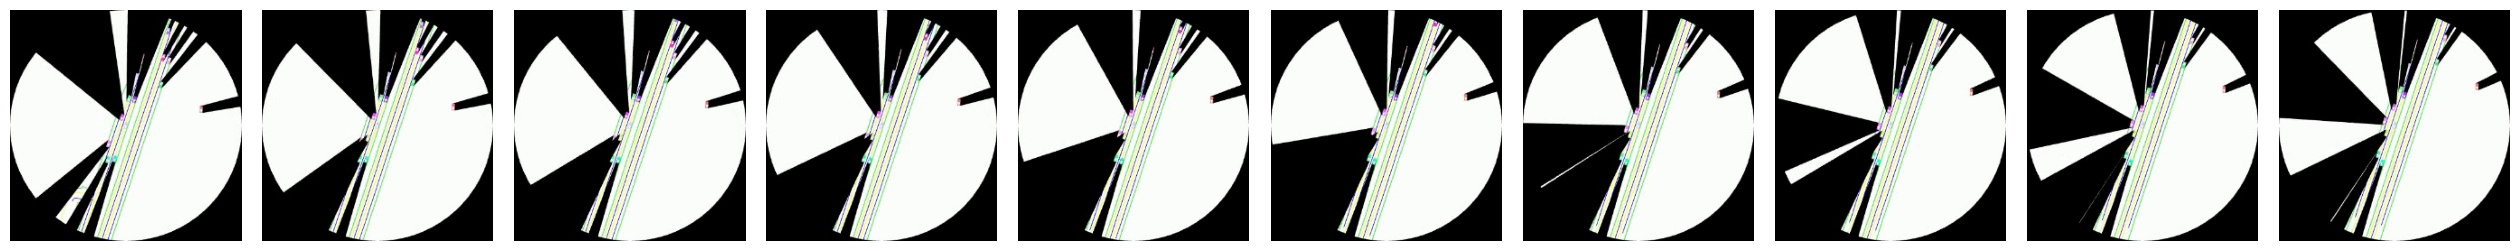

In [3]:
from openstl.utils import show_video_line

train_x, train_y = train_loader.dataset[4]

train_x = train_x.numpy()

# show the given frames from an example
example_idx = 0
print(train_x.shape)
start = 30-10
show_video_line(train_x[start:], ncols=10, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

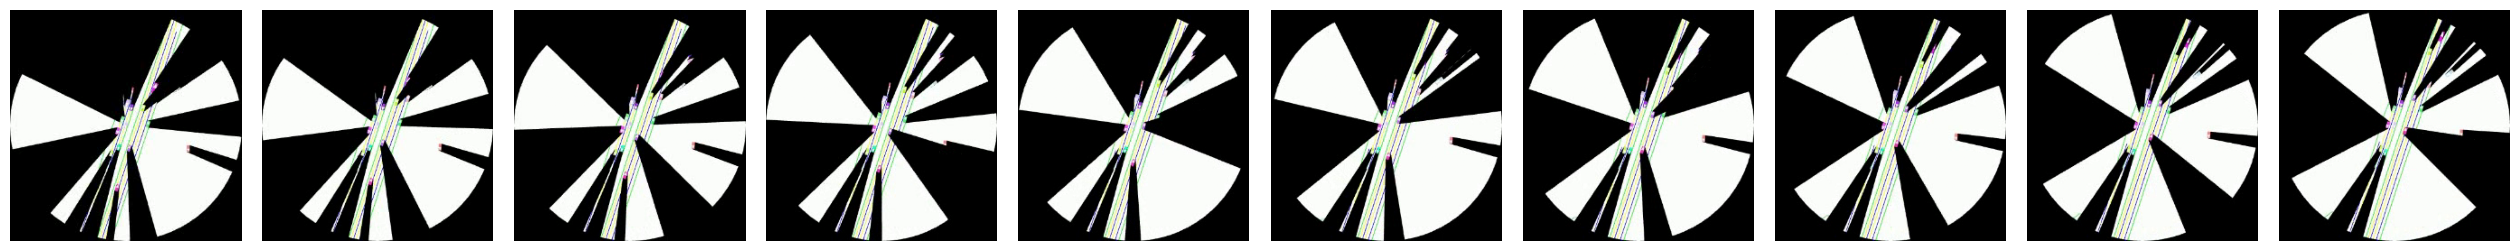

In [4]:
show_video_line(train_x, ncols=10, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

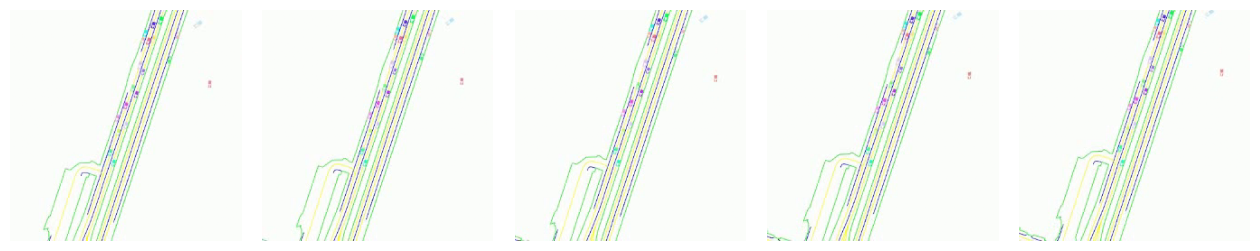

In [5]:
# show the future frames from an example
train_y = train_y.numpy()
show_video_line(train_y, ncols=5, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

## Train and evaluate

In [6]:
# exp_name = 'predformer_baseline'# 'predformer_baseline'

# feature_img_length = 20

# custom_training_config = {
#     'pre_seq_length': feature_img_length,
#     'aft_seq_length': aft_seq_length,
#     'total_length': feature_img_length + aft_seq_length,
#     'batch_size': batch_size,
#     'val_batch_size': batch_size,
#     'epoch': 50,
#     'lr': 0.001,   
#     'metrics': ['mse', 'mae', 'psnr'], #['mse', 'mae', 'ssim'],
#     'ex_name': exp_name,
#     'dataname': 'custom',
#     'in_shape': [feature_img_length, 3, frame_size, frame_size],
#     'device': 'cuda:1',
#     #'gpus': [1]
# }


# custom_model_config = {
#     'method': 'PredFormer',
#     # image h w c
#     'height': frame_size,
#     'width': frame_size,
#     'num_channels': 3,
#     # video length in and out
#     'pre_seq': feature_img_length,
#     'after_seq': aft_seq_length,
#     # patch size
#     'patch_size': 8,
#     'dim': 256, 
#     'heads': 8,
#     'dim_head': 32,
#     # dropout
#     'dropout': 0.0,
#     'attn_dropout': 0.0,
#     'drop_path': 0.0,
#     'scale_dim': 4,
#     # depth
#     'depth': 1,
#     'Ndepth': 6 # For FullAttention-24, for BinaryST, BinaryST, FacST, FacTS-12, for TST,STS-8, for TSST, STTS-6

# }



In [7]:
exp_name = 'tau_30frame_baseline'# 'predformer_baseline'

feature_img_length = 30

custom_training_config = {
    'pre_seq_length': feature_img_length,
    'aft_seq_length': aft_seq_length,
    'total_length': feature_img_length + aft_seq_length,
    'batch_size': batch_size,
    'val_batch_size': batch_size,
    'epoch': 20,
    'lr': 0.001,   
    'metrics': ['mse', 'mae', 'psnr', 'ssim'],
    'ex_name': exp_name,
    'dataname': 'custom',
    'in_shape': [feature_img_length, 3, frame_size, frame_size],
    'gpus': [1]
}

# custom_model_config = {
#     # For MetaVP models, the most important hyperparameters are: 
#     # N_S, N_T, hid_S, hid_T, model_type
#     'method': 'SimVP',
#     # Users can either using a config file or directly set these hyperparameters 
#     # 'config_file': 'configs/custom/example_model.py',
    
#     # Here, we directly set these parameters
#     'spatio_kernel_enc': 3,
#     'spation_kernel_dec': 3,
#     'model_type': 'gSTA',
#     'N_S': 4,
#     'N_T': 8,
#     'hid_S': 64,
#     'hid_T': 512
# }

custom_model_config = {
    'method': 'TAU',
    'spatio_kernel_enc': 3,
    'spatio_kernel_dec': 3,
    'model_type': 'tau',
    'hid_S': 64,
    'hid_T': 512,
    'N_T': 8,
    'N_S': 4,
    'alpha': 0.1,
    'drop_path': 0,
}


In [8]:
from openstl.api import BaseExperiment
from openstl.utils import create_parser, default_parser

args = create_parser().parse_args([])
config = args.__dict__

# update the training config
config.update(custom_training_config)
# update the model config
# config.update(method = 'PredFormer', model_config=custom_model_config)
config.update(custom_model_config)
# fulfill with default values
default_values = default_parser()
for attribute in default_values.keys():
    if config[attribute] is None:
        config[attribute] = default_values[attribute]

print('configs loaded')

configs loaded


In [9]:
exp = BaseExperiment(args, dataloaders=(train_loader, val_loader, test_loader)) #, strategy='auto')
print("Experiment loaded")

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


Experiment loaded


In [10]:
print('>'*35 + ' training ' + '<'*35)
# exp.train()

>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> training <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<


In [11]:
batch_size = 1

custom_training_config = {
    'pre_seq_length': feature_img_length,
    'aft_seq_length': aft_seq_length,
    'total_length': feature_img_length + aft_seq_length,
    'batch_size': batch_size,
    'val_batch_size': batch_size,
    'epoch': 10,
    'lr': 0.001,   
    'metrics': ['mse', 'mae', 'psnr', 'ssim'],
    'ex_name': exp_name,
    'dataname': 'custom',
    'in_shape': [feature_img_length, 3, frame_size, frame_size],
    'gpus': [1],
    'test': True,
    'fps': False,
}

args = create_parser().parse_args([])
config = args.__dict__

# update the training config
config.update(custom_training_config)
# update the model config
config.update(custom_model_config)
# fulfill with default values
default_values = default_parser()
for attribute in default_values.keys():
    if config[attribute] is None:
        config[attribute] = default_values[attribute]

exp = BaseExperiment(args, dataloaders=(train_loader, val_loader, test_loader), strategy='auto')

print('>'*35 + ' testing  ' + '<'*35)
# with torch.no_grad():
#     results = exp.test()


Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> testing  <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<


In [12]:
# print(results)
torch.cuda.empty_cache()
import gc
gc.collect()
print('done')

done


In [13]:
# info, flops, fps, dash_line = exp.display_method_info(args)
# print('FPS: ', fps)

## Visualization

In [14]:
import numpy as np
from openstl.utils import show_video_line

# exp_name = 'tau_10ep_color'
#results.clear()

import gc
gc.collect()

exp_name = 'tau_30frame_baseline'

# show the given frames from an example
inputs = np.load('./work_dirs/'+exp_name+'/saved/inputs.npy')
preds = np.load('./work_dirs/'+exp_name+'/saved/preds.npy')
trues = np.load('./work_dirs/'+exp_name+'/saved/trues.npy')


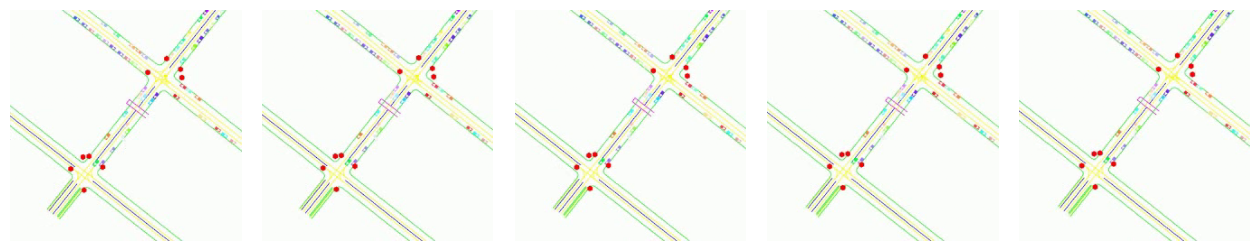

In [15]:
example_idx = 27
show_video_line(trues[example_idx], ncols=aft_seq_length, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.005319774..1.0338523].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0023169518..1.0274855].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.04405701..1.0279573].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.02622217..1.0289598].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0032349825..1.028163].


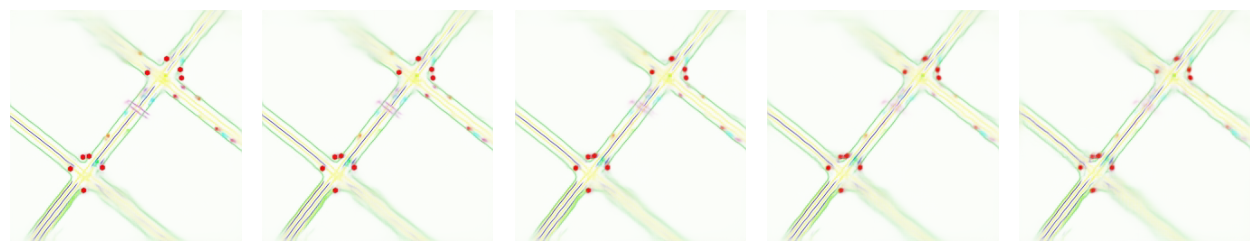

In [16]:
# example_idx = 0
show_video_line(preds[example_idx], ncols=aft_seq_length, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

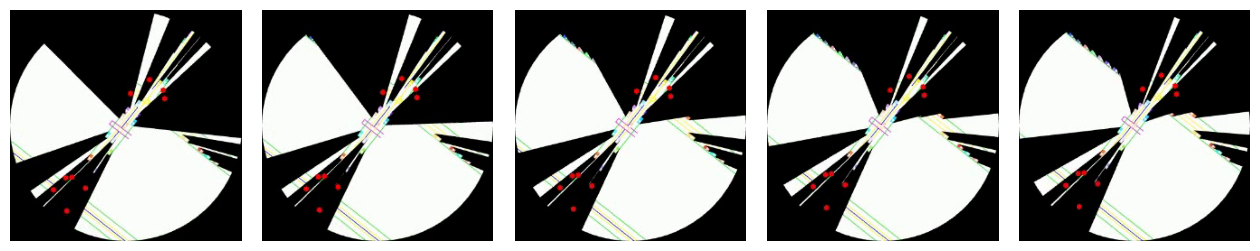

In [17]:
# example_idx = 0
show_video_line(inputs[example_idx][10:], ncols=aft_seq_length, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

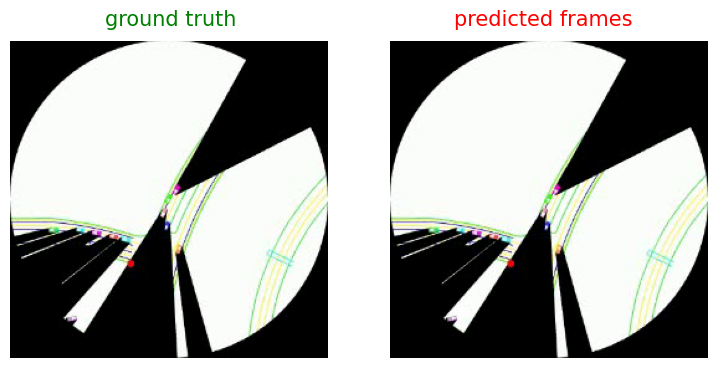

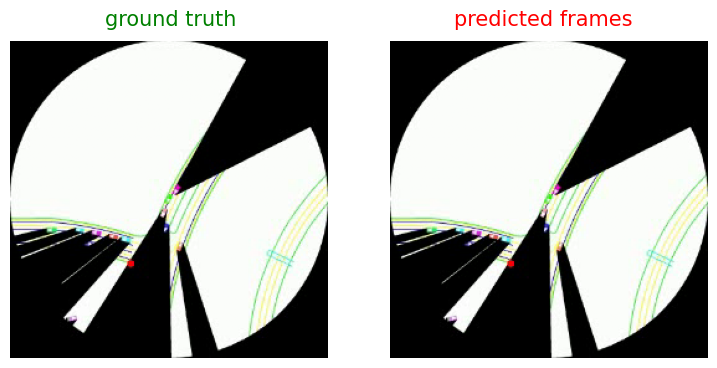

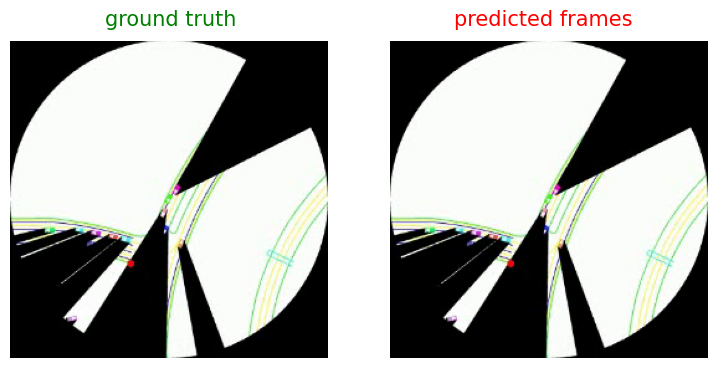

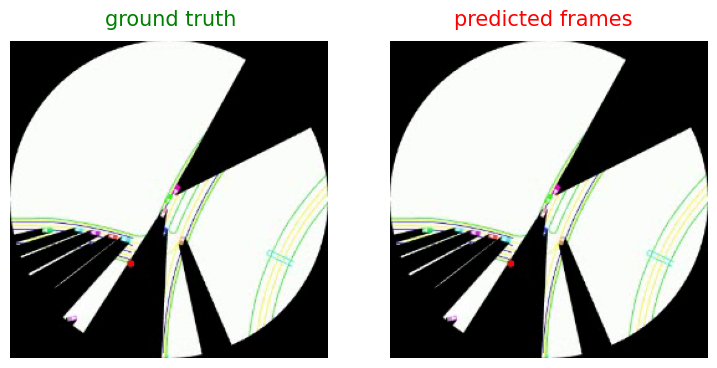

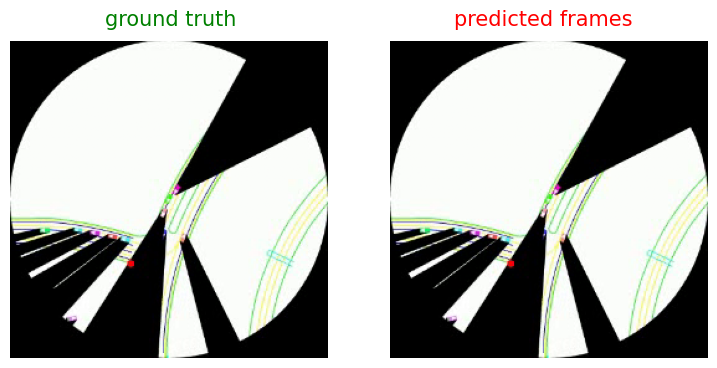

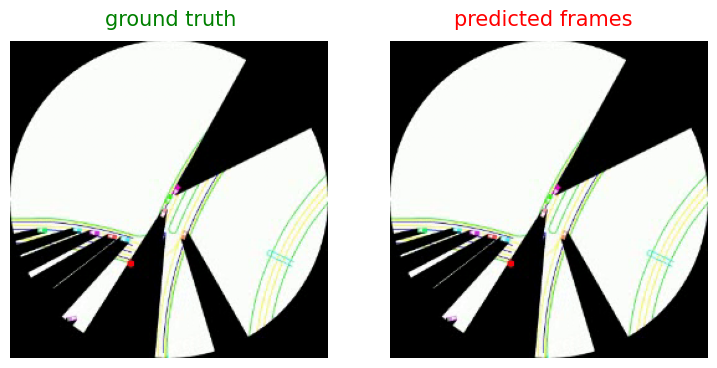

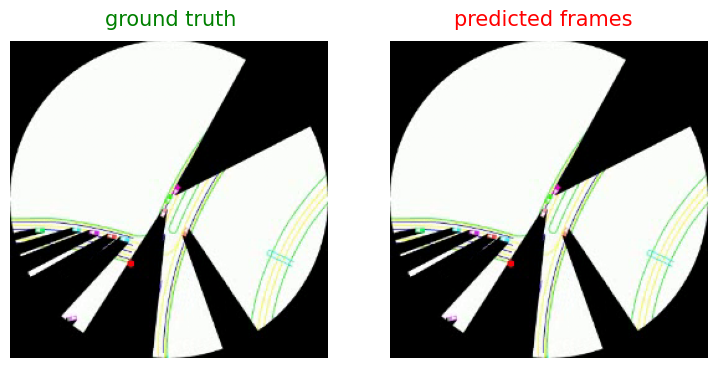

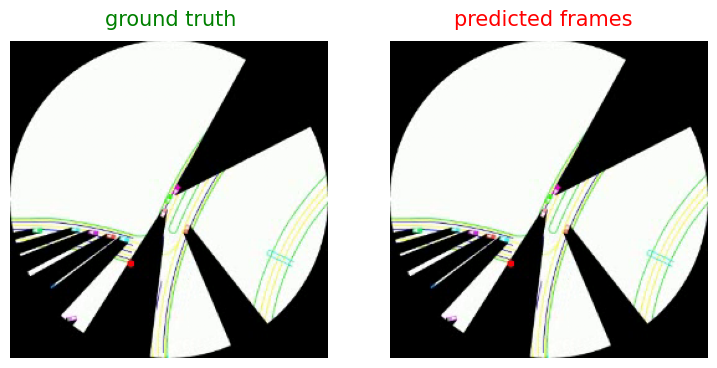

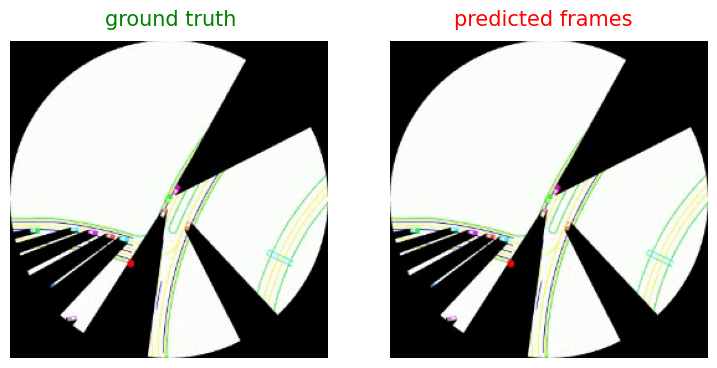

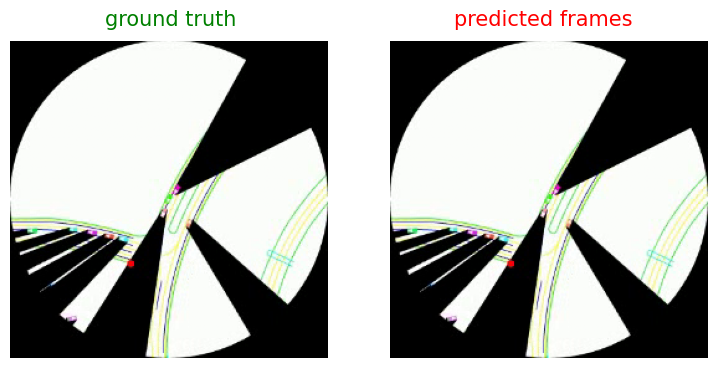

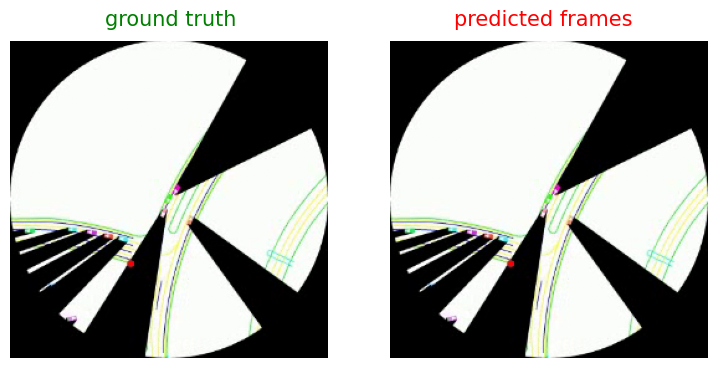

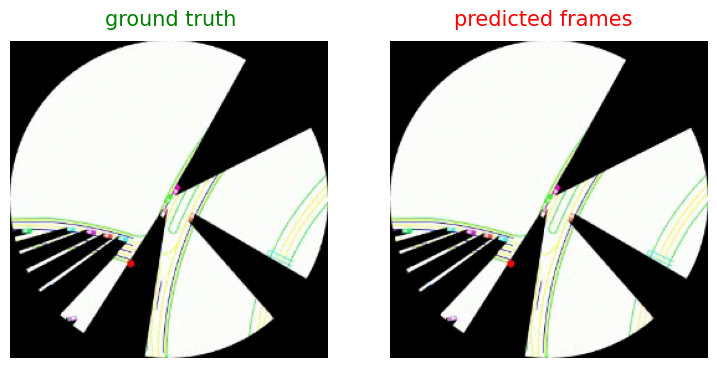

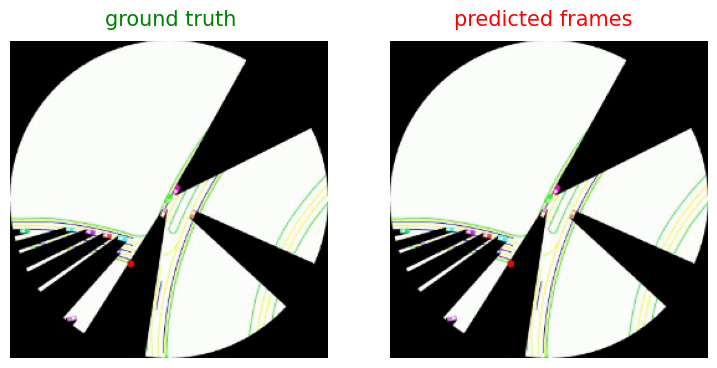

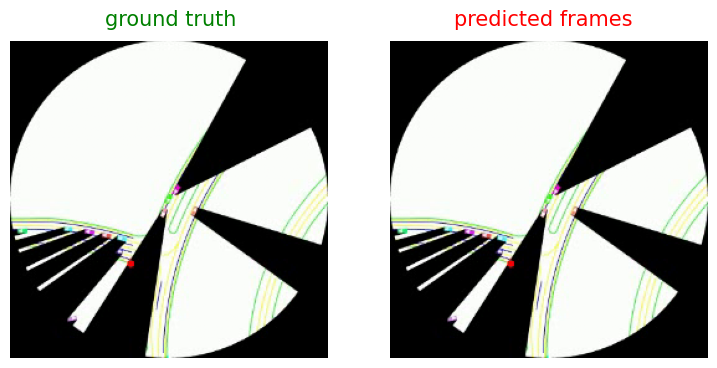

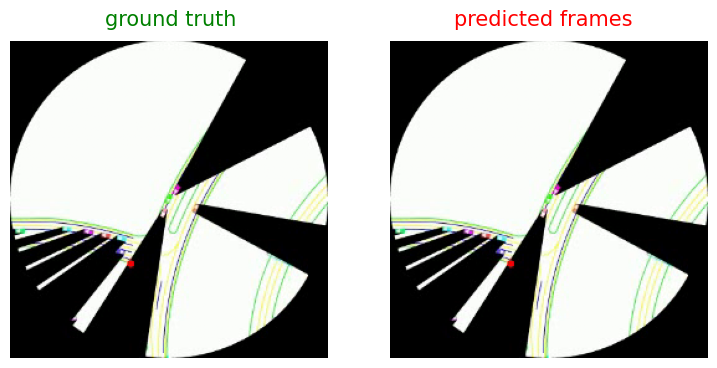

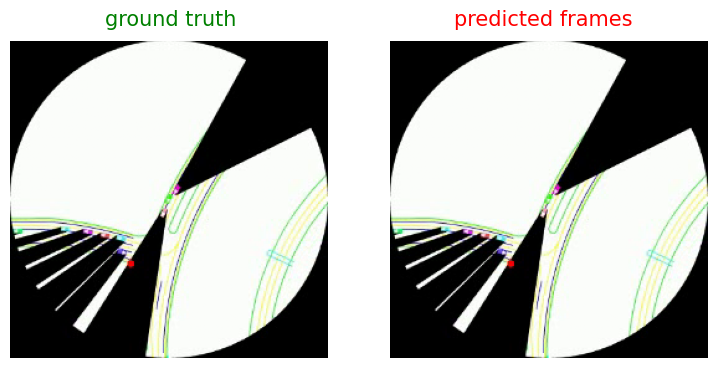

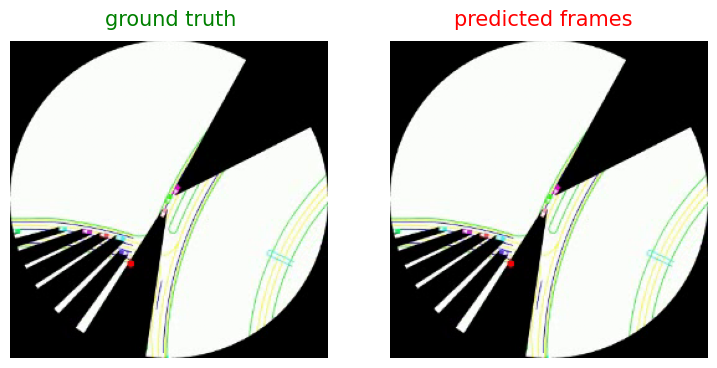

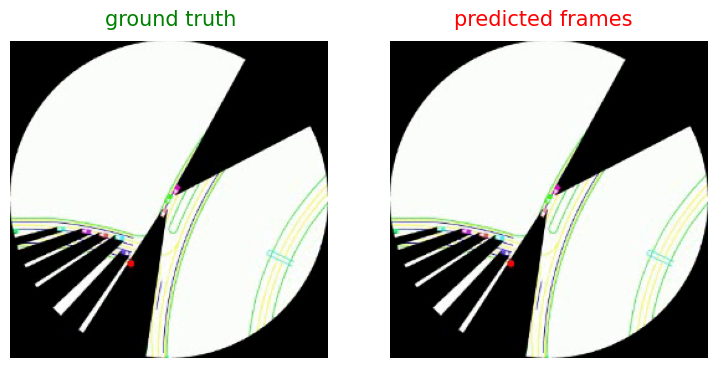

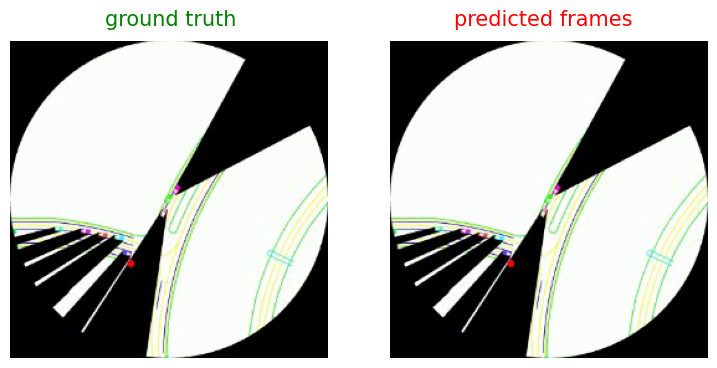

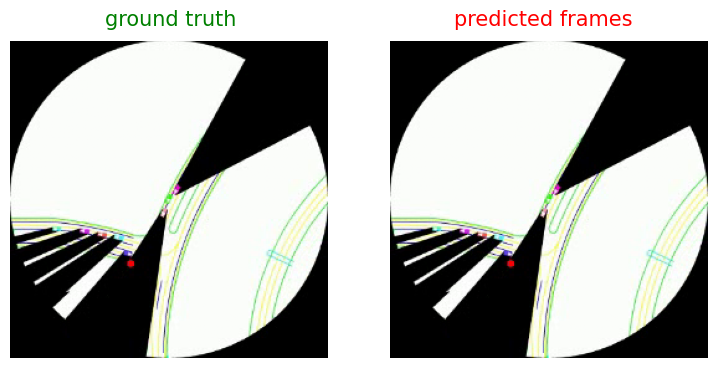

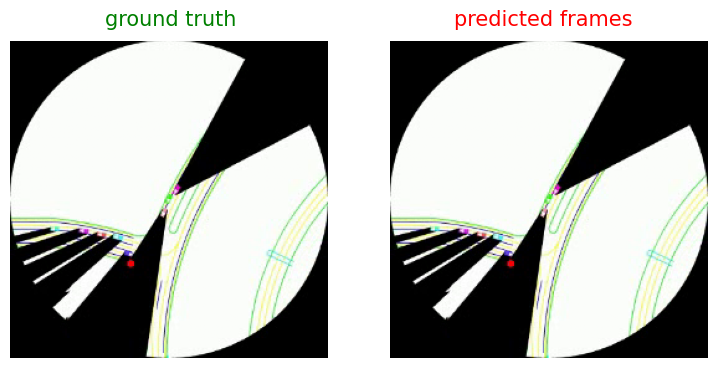

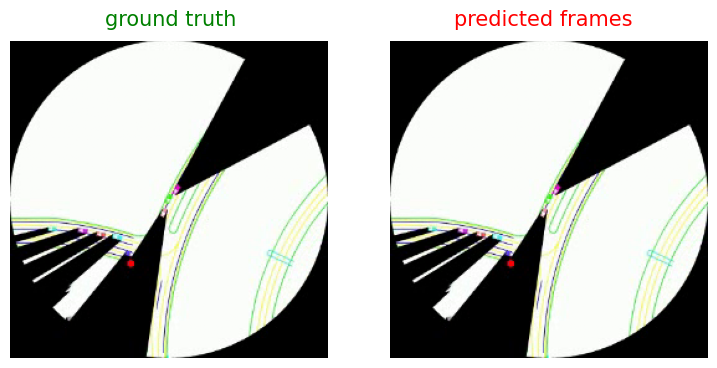

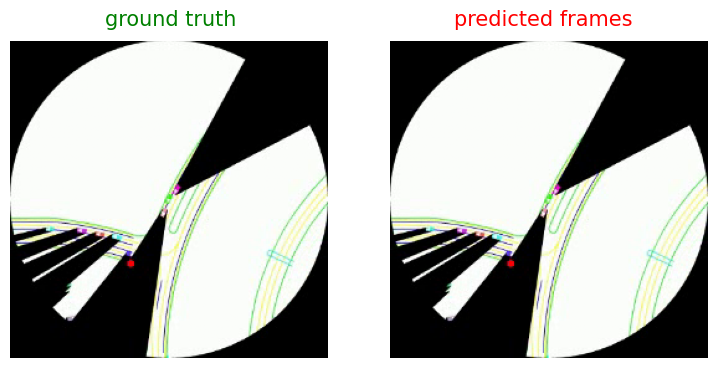

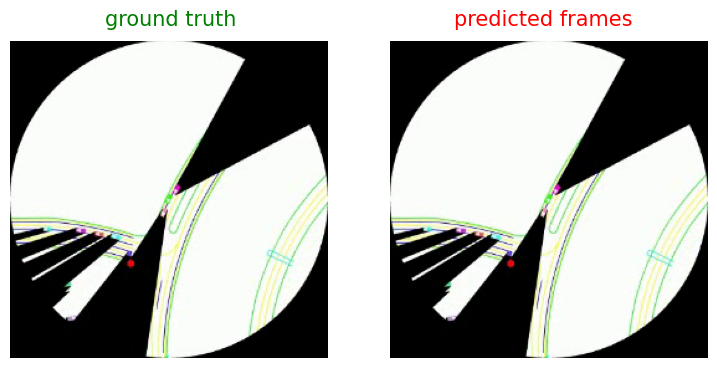

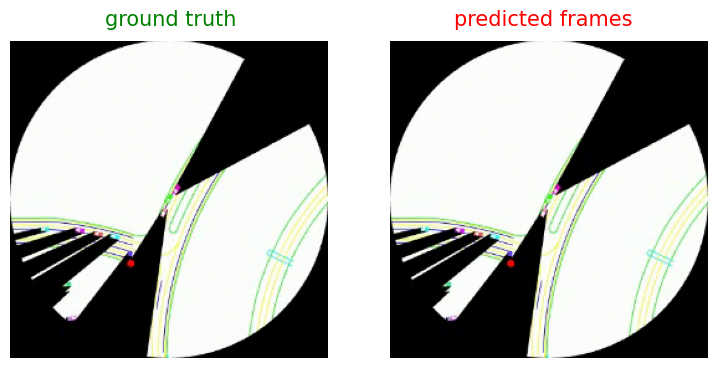

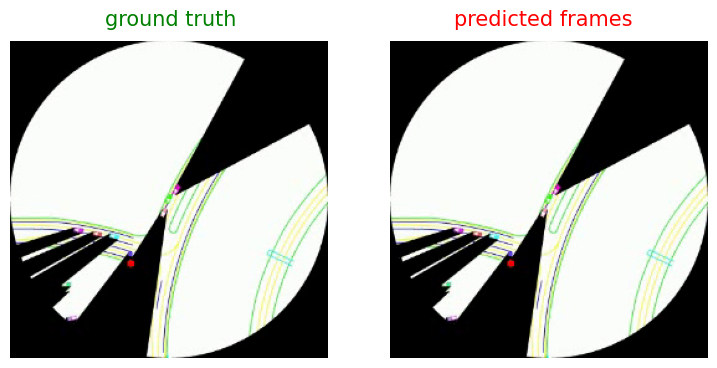

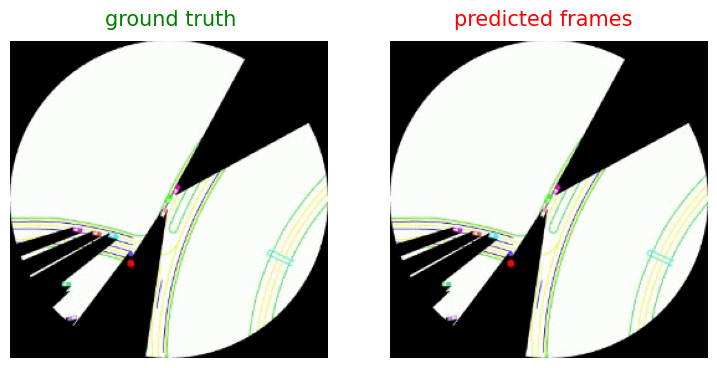

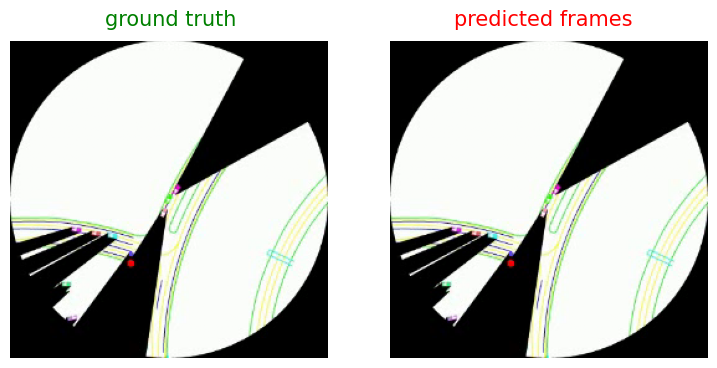

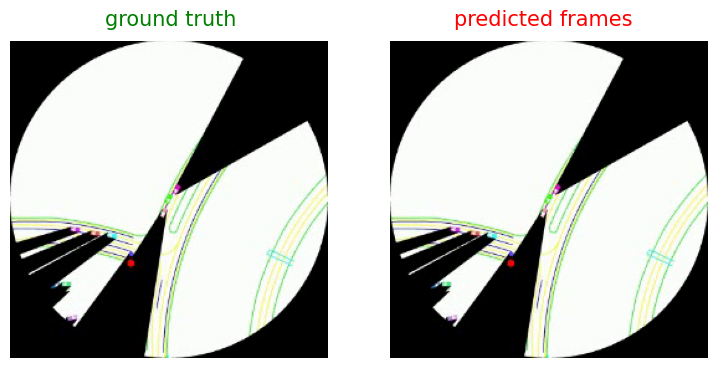

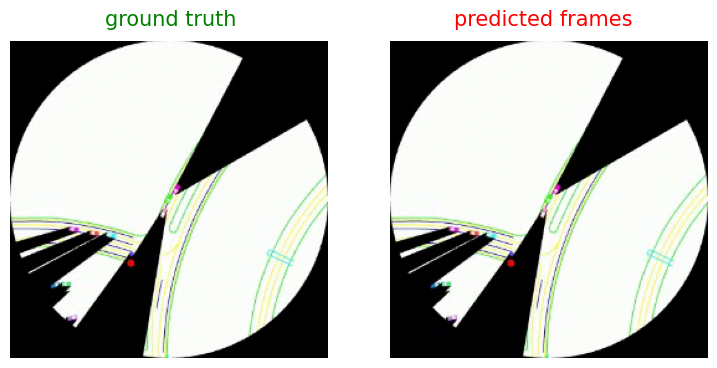

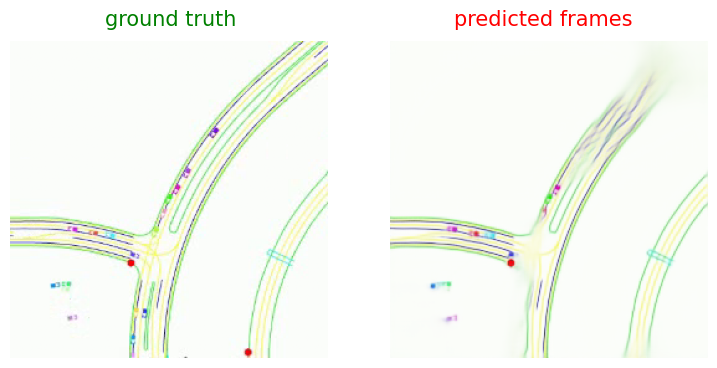

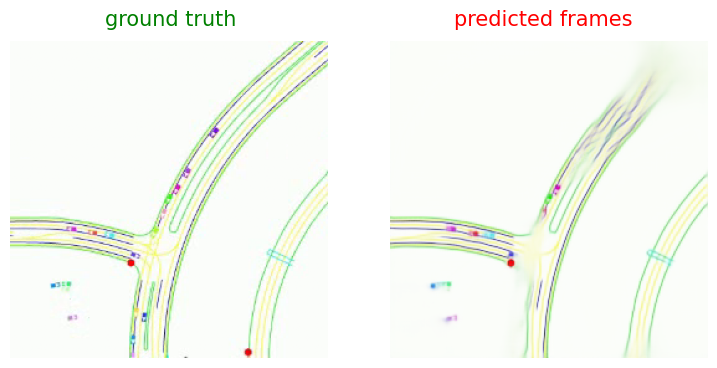

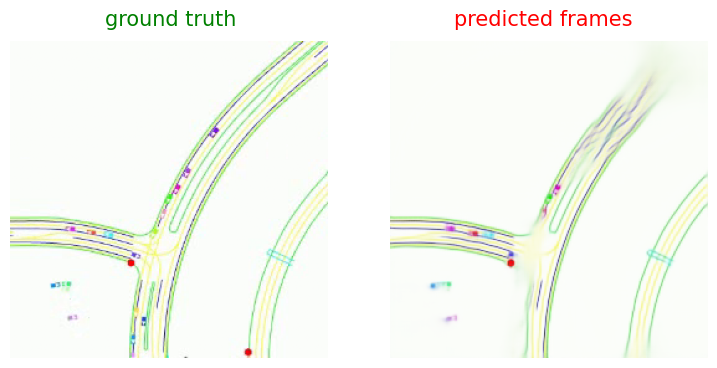

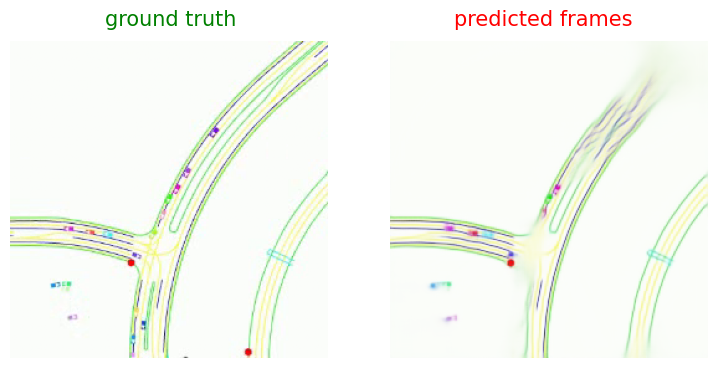

In [14]:
from openstl.utils import show_video_gif_multiple

example_idx = 0
show_video_gif_multiple(inputs[example_idx], trues[example_idx], preds[example_idx], use_rgb=True, out_path='example.gif')

In [15]:
# print(trues[example_idx])